# SECOND — H3a и H3b: строгая проверка детерминизма

Версия с `torch.use_deterministic_algorithms(True)`, детерминированным cuDNN, конфигурацией cuBLAS и сохранением RNG. **Использует отдельную папку результатов**, не перезаписывает прежний эксперимент. Запуск: **Restart Kernel → Run All**. Включено `FINETUNE_EPOCHS=25`. Два повторных коротких прогона проверяют побитовое совпадение весов для Original и Extended. Они не доказывают автоматически совпадение полного 25-эпохового запуска.


## 1. Пути, оригинальные checkpoints и неизменённый SECOND

Первый блок только читает сохранённые протоколы/manifest и подготавливает зависимости, не меняя HPO.

In [1]:
"""Controlled SECOND ROI context experiments (validation only).

H3a: Evaluate the unchanged trained Tiny Siamese with original crops and
      VERIFIED original-image context (+8/+16/+32px), including black-halo control.
H3b: Paired fine-tuning from each original seed checkpoint, using identical
      prepared train/validation ROI IDs and optimisation budget for the original
      crop and +32px real-context crop. No test data or HPO modifications.
"""
from __future__ import annotations

# Strict reproducibility requires a fresh kernel, before any torch import.
import os
import sys
if 'torch' in sys.modules:
    raise RuntimeError('PyTorch already imported. Restart Kernel and Run All before strict deterministic test.')
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'


import copy
import hashlib
import inspect
import json
import random
import re
import sys
from collections import defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt

# ========================= CONFIGURATION =========================
PROJECT_ROOT = Path('/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence')
SEARCH_NAME = 'second_oracle_bounded21_e15_25_40_65_bf16_w4_v1'
SEEDS = (42, 123, 777)
CONTEXT_PX = (0, 8, 16, 32)
H3B_PADDING = 32                # train & evaluate the larger-context arm on this margin
MAX_VAL_ROIS = 600             # None = all validation; same ROI indices in all arms
MAX_TRAIN_ROIS = 800           # None = all train, quick initial controlled test
FINETUNE_EPOCHS = 25            # SAME number of extra epochs per arm and seed
FINETUNE_LR = 1e-4
FINETUNE_BATCH_SIZE = 8        # logical batches, native-size ROI handled individually
FINETUNE_WEIGHT_DECAY = 1e-3
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
USE_BF16 = True
RUN_H3B = True                 # False runs ONLY frozen H3a
ALIGNMENT_MAE_TOLERANCE = 1.0  # verify exact native crop vs two original RGBs
MIN_VAL_MATCHED = 80
MIN_TRAIN_MATCHED = 120
REQUIRE_ALIGNMENT_FRACTION = 0.75
BOOTSTRAP_REPLICATES = 300
RANDOM_STATE = 2026
# ================================================================

# Enforce deterministic kernels or fail; do not silently fall back.
DETERMINISM_PROTOCOL = {
    'version': 1,
    'cublas_workspace_config': os.environ['CUBLAS_WORKSPACE_CONFIG'],
    'cudnn_deterministic': True,
    'cudnn_benchmark': False,
    'tf32': False,
    'deterministic_algorithms': True,
}
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True)
assert torch.are_deterministic_algorithms_enabled()
print('STRICT DETERMINISM:', DETERMINISM_PROTOCOL)

ROOT = PROJECT_ROOT.expanduser().resolve()
sys.path.insert(0, str(ROOT / 'src'))
from satchange.models import TinySiameseChangeClassifier
from satchange.semantic.data import SemanticROIDataset
from satchange.semantic.second import discover_second
from satchange.semantic.training import logical_forward, semantic_loss
from satchange.utils import load_config

SEARCH = ROOT / 'artifacts/hyperparameter_search/semantic/tiny_siamese_second' / SEARCH_NAME
OUT = ROOT / 'artifacts/debug/tiny_second_context_h3a_h3b_deterministic_v1' / SEARCH_NAME
OUT.mkdir(parents=True, exist_ok=True)


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def sha256(path):
    obj = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            obj.update(b)
    return obj.hexdigest()


def hash_obj(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()


summary_file = SEARCH / 'final_training_summary.json'
protocol_file = SEARCH / 'pipeline_protocol.json'
if not summary_file.is_file() or not protocol_file.is_file():
    raise FileNotFoundError('Missing completed Tiny training search: ' + str(SEARCH))
summary, protocol = read_json(summary_file), read_json(protocol_file)
if not summary.get('complete') or protocol.get('context',{}).get('task') != 'semantic_roi_classification':
    raise RuntimeError('Need a COMPLETE semantic ROI classification training experiment.')
base = protocol['base']
ident_file = SEARCH / 'notebook_bounded21_protocol.json'
ident = read_json(ident_file).get('identity',{}) if ident_file.is_file() else {}
possible = [ident.get('dataset_root'), protocol.get('dataset_root'),
            protocol.get('context',{}).get('dataset_root'),
            base.get('dataset_root')]
possible.extend(r.get('parameters',{}).get('dataset_root') for r in summary.get('results',[]))
paths = set()
for item in possible:
    if not isinstance(item, str) or not item.strip(): continue
    p = Path(item).expanduser()
    if not p.is_absolute(): p = ROOT / p
    if p.is_file() and p.suffix == '.json': paths.add(p.resolve())
if len(paths) != 1:
    raise RuntimeError('Cannot unambiguously resolve training manifest: ' + repr(sorted(map(str,paths))))
MANIFEST = next(iter(paths))
if ident.get('manifest_sha256') and sha256(MANIFEST) != ident['manifest_sha256']:
    raise RuntimeError('Prepared manifest changed since original training.')

config = copy.deepcopy(load_config(ROOT/'configs/tiny_siamese_change_classifier.yaml'))
config.update(copy.deepcopy(base['semantic_config']))
config['dropout'] = base['model_parameters']['dropout']
config.setdefault('training',{}).update({k:copy.deepcopy(base[k]) for k in
    ('batch_size','num_workers','precision','tf32','class_weights') if k in base})
classes = tuple(config['classes'])
K = len(classes)
val_ds = SemanticROIDataset(MANIFEST,'val',config)
train_ds = SemanticROIDataset(MANIFEST,'train',config)
raw_splits = discover_second(ROOT/'data/SECOND')
raw_scenes = [r for members in raw_splits.values() for r in members if isinstance(r,dict)]
raw_by_id = {}
for item in raw_scenes:
    v = str(item.get('sample_id',''))
    for alias in {v,v.split('/')[-1]}:
        if alias: raw_by_id.setdefault(alias,[]).append(item)

print('Model:',classes,'| train:',len(train_ds),'| val:',len(val_ds))
print('Manifest:',MANIFEST,'| original source scenes:',len(raw_scenes))
print('No SECOND test split will be used.')

STRICT DETERMINISM: {'version': 1, 'cublas_workspace_config': ':4096:8', 'cudnn_deterministic': True, 'cudnn_benchmark': False, 'tf32': False, 'deterministic_algorithms': True}
Model: ('non-vegetated ground surface', 'tree', 'low vegetation', 'water', 'buildings', 'playgrounds') | train: 26867 | val: 5904
Manifest: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/data/SECOND_semantic_cache/0590eed622ef37dcdf469c09be6cd5d83186109d499e755590f1177569d7f7fc/rois/prepared.json | original source scenes: 2968
No SECOND test split will be used.


## 2. Проверка соответствия ROI исходным сценам

Строгое сопоставление оригинальных изображений RGB `im1` и `im2` с готовыми ROI. Вся проверка проводится до начала H3b обучения.

In [2]:
# ------------------ original-scene aligned context ------------------
manifest_doc = read_json(MANIFEST)
records = {}
def visit(obj):
    if isinstance(obj,dict):
        v=obj.get('sample_id')
        if isinstance(v,str): records.setdefault(v,obj)
        for child in obj.values(): visit(child)
    elif isinstance(obj,list):
        for child in obj: visit(child)
visit(manifest_doc)


def source_path(record, keys):
    for k in keys:
        v=record.get(k)
        if v is None: continue
        p=Path(str(v)).expanduser()
        if not p.is_absolute():
            attempts = (ROOT/p, ROOT/'data/SECOND'/p, MANIFEST.parent/p)
            p = next((x for x in attempts if x.is_file()),p)
        if p.is_file(): return p.resolve()
    return None


def find_source(row, sample_id):
    hints=[]
    for parent in (row,row.get('roi',{}),row.get('source',{})):
        if not isinstance(parent,dict): continue
        for key in ('source_sample_id','source_id','source_scene','scene_id',
                    'original_sample_id','source_image_id'):
            val=parent.get(key)
            if isinstance(val,str): hints.append(val)
    # Prefer exact split-aware IDs (e.g. train/00197); train and val may
    # contain the same basename, but they are different source scenes.
    hints.append(sample_id)
    for hint in hints:
        matches=raw_by_id.get(hint,[])
        if len(matches)==1:return matches[0]
    candidates={}
    for hint in [*hints,sample_id.split('/')[-1]]:
        for r in raw_by_id.get(hint.split('/')[-1],[]):
            candidates[str(r.get('sample_id'))]=r
    if len(candidates)==1: return next(iter(candidates.values()))
    return None


def box_candidates(record,h,w):
    vals=[]
    for parent in (record,record.get('roi',{}),record.get('source',{})):
        if not isinstance(parent,dict): continue
        for name in ('bbox_xyxy','crop_xyxy','crop_box','roi_box','bbox','bounds'):
            v=parent.get(name)
            if isinstance(v,(list,tuple)) and len(v)==4:
                try:
                    a,b,c,d=[int(x) for x in v]
                    vals.extend(((a,b,c,d),(b,a,d,c)))
                except (TypeError,ValueError): pass
        for names in (('x0','y0','x1','y1'),('xmin','ymin','xmax','ymax'),
                      ('left','top','right','bottom')):
            if all(k in parent for k in names):
                try: vals.append(tuple(int(parent[k]) for k in names))
                except (ValueError,TypeError): pass
    return list(dict.fromkeys((a,b,c,d) for a,b,c,d in vals if
        a>=0 and b>=0 and c-a==w and d-b==h))


@lru_cache(maxsize=128)
def rgb(path):
    with Image.open(path) as im: return np.array(im.convert('RGB'),dtype=np.uint8)


def sample_rgb_u8(t):
    if not isinstance(t,torch.Tensor) or t.ndim!=3 or t.shape[0]!=3:
        raise ValueError('Expected float RGB [3,H,W] from SemanticROIDataset')
    if not torch.isfinite(t).all() or t.min()<0 or t.max()>1:
        raise ValueError('Non-finite/out-of-range normalized RGB')
    return np.rint(t.detach().cpu().permute(1,2,0).numpy()*255).clip(0,255).astype(np.uint8)


def compare_mae(region, patch):
    if region.shape != patch.shape: return float('inf')
    return float(np.mean(np.abs(region.astype(np.int16)-patch.astype(np.int16))))


def locate_patch(img,patch):
    # Exact source alignment is verified twice (before and after) below.
    import cv2
    if patch.shape[0]>img.shape[0] or patch.shape[1]>img.shape[1]: return []
    gray_full=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    gray_patch=cv2.cvtColor(patch,cv2.COLOR_RGB2GRAY)
    score=cv2.matchTemplate(gray_full,gray_patch,cv2.TM_SQDIFF_NORMED)
    found=[]
    for _ in range(4):
        minimum, _, (x,y), _ = cv2.minMaxLoc(score)
        if not np.isfinite(minimum) or minimum>0.003: break
        found.append((x,y,x+patch.shape[1],y+patch.shape[0]))
        xx0,xx1=max(0,x-3),min(score.shape[1],x+4)
        yy0,yy1=max(0,y-3),min(score.shape[0],y+4)
        score[yy0:yy1,xx0:xx1]=1
    return found


def align_one(ds, index):
    s=ds[int(index)]
    sid=str(s.get('sample_id',index))
    row=records.get(sid,{})
    if not isinstance(row,dict): row={}
    src=find_source(row,sid)
    if not src: return None, 'source scene not identifiable'
    bpath=source_path(src,('im1','before','before_image','before_path','image1'))
    apath=source_path(src,('im2','after','after_image','after_path','image2'))
    if bpath is None or apath is None: return None, 'original im1/im2 unavailable'
    patch_b,patch_a=sample_rgb_u8(s['before']),sample_rgb_u8(s['after'])
    if patch_b.shape != patch_a.shape: return None, 'input before/after shapes disagree'
    full_b,full_a=rgb(str(bpath)),rgb(str(apath))
    if full_b.shape != full_a.shape: return None, 'source before/after dimensions differ'
    h,w=patch_b.shape[:2]
    if full_b.shape[0]<h or full_b.shape[1]<w:return None,'source smaller than ROI'
    positions=box_candidates(row,h,w)
    # If no verified explicit location, find the original crop by exact RGB matching.
    positions+=locate_patch(full_b,patch_b)
    positions=list(dict.fromkeys(positions))
    good=[]
    for x0,y0,x1,y1 in positions:
        if x1>full_b.shape[1] or y1>full_b.shape[0]: continue
        if (compare_mae(full_b[y0:y1,x0:x1],patch_b)<=ALIGNMENT_MAE_TOLERANCE and
            compare_mae(full_a[y0:y1,x0:x1],patch_a)<=ALIGNMENT_MAE_TOLERANCE):
            good.append((x0,y0,x1,y1))
    if len(good)!=1: return None,'cannot uniquely verify BOTH RGB dates (%d candidates)'%len(good)
    return {'index':int(index),'sample_id':sid,'scene_id':str(src.get('sample_id',sid)),
       'source_before':str(bpath),'source_after':str(apath),'box':good[0],
       'shape':(h,w),'before_label':int(s['before_label']),'after_label':int(s['after_label'])}, None


def selected_indices(count, max_count, seed):
    rng=np.random.default_rng(seed)
    n=count if max_count is None else min(count,max_count)
    return np.sort(rng.choice(count,size=n,replace=False)).tolist()


def align_split(ds,ids,description):
    success,fail=[],defaultdict(int)
    for n,index in enumerate(ids,1):
        item,error=align_one(ds,index)
        if item is not None: success.append(item)
        else: fail[error]+=1
        if n%100==0 or n==len(ids): print(description,'alignment',n,'/',len(ids),'matched',len(success))
    report={'split':description,'requested':len(ids),'matched':len(success),
            'fraction':len(success)/max(1,len(ids)),'failures':dict(fail)}
    (OUT/f'alignment_{description}.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print(description,'alignment report:',report)
    limit=MIN_TRAIN_MATCHED if description=='train' else MIN_VAL_MATCHED
    if len(success)<limit or report['fraction']<REQUIRE_ALIGNMENT_FRACTION:
        raise RuntimeError('Not enough VERIFIED original-scene ROI alignments for '+description+
           '. This is NOT a dataset/architecture failure. Need real source metadata / coordinates '
           'from src/satchange/semantic/second.py and data.py. Do not use artificial padding '
           'as substitute for satellite context. Failure counts: '+repr(dict(fail)))
    return success


val_ids=selected_indices(len(val_ds),MAX_VAL_ROIS,RANDOM_STATE)
train_ids=selected_indices(len(train_ds),MAX_TRAIN_ROIS,RANDOM_STATE+1) if RUN_H3B else []
val_meta=align_split(val_ds,val_ids,'val')
train_meta=align_split(train_ds,train_ids,'train') if RUN_H3B else []
if RUN_H3B:
    train_scene_set = {r['scene_id'] for r in train_meta}
    val_scene_set = {r['scene_id'] for r in val_meta}
    scene_overlap = sorted(train_scene_set & val_scene_set)
    print('Train/validation source-scene overlap:',len(scene_overlap),'scenes')
    if scene_overlap:
        print('WARNING: scene-level validation leakage may exist in the original split. '
              'H3b conclusions are exploratory unless split provenance establishes independence.')
    (OUT/'source_scene_overlap.json').write_text(json.dumps({'overlap_count':len(scene_overlap),
         'example_scene_ids':scene_overlap[:20]},indent=2),encoding='utf-8')


@lru_cache(maxsize=4096)
def cached_mask(split,index):
    dataset = val_ds if split=='val' else train_ds
    return dataset[int(index)]['mask'].detach().cpu().numpy().copy()


def generate_roi(meta, pad, black_halo=False):
    x0,y0,x1,y1=meta['box']
    fb,fa=rgb(meta['source_before']),rgb(meta['source_after'])
    H,W=fb.shape[:2]
    xx0=max(0,x0-pad);yy0=max(0,y0-pad)
    xx1=min(W,x1+pad);yy1=min(H,y1+pad)
    b=fb[yy0:yy1,xx0:xx1].copy()
    a=fa[yy0:yy1,xx0:xx1].copy()
    if black_halo:
        b[:]=0;a[:]=0
        b[y0-yy0:y1-yy0,x0-xx0:x1-xx0]=fb[y0:y1,x0:x1]
        a[y0-yy0:y1-yy0,x0-xx0:x1-xx0]=fa[y0:y1,x0:x1]
    orig_mask=cached_mask(meta.get('_split','val'),meta['index'])
    if orig_mask.shape!=(1,y1-y0,x1-x0): raise RuntimeError('Sample mask mismatch')
    mask=np.zeros((1,yy1-yy0,xx1-xx0),dtype=np.float32)
    mask[:,y0-yy0:y1-yy0,x0-xx0:x1-xx0]=orig_mask
    if not mask.any():raise RuntimeError('Empty changed support')
    return {'before':torch.from_numpy(b.copy()).permute(2,0,1).float().div_(255),
            'after':torch.from_numpy(a.copy()).permute(2,0,1).float().div_(255),
            'mask':torch.from_numpy(mask),
            'before_label':meta['before_label'],'after_label':meta['after_label']}

# Check pads preserve original RGB and masks bit for bit (up to original quantisation).
for m in val_meta[:min(5,len(val_meta))]:
    ref=val_ds[m['index']]
    built=generate_roi(m,0)
    if not torch.equal(ref['mask'].float(),built['mask']):raise RuntimeError('Mask reconstruction changed baseline')
    if (ref['before']-built['before']).abs().max().item()>1/255+1e-6:
        raise RuntimeError('RGB reconstruction differs from the original dataset')

val alignment 100 / 600 matched 100
val alignment 200 / 600 matched 200
val alignment 300 / 600 matched 300
val alignment 400 / 600 matched 400
val alignment 500 / 600 matched 500
val alignment 600 / 600 matched 600
val alignment report: {'split': 'val', 'requested': 600, 'matched': 600, 'fraction': 1.0, 'failures': {}}
train alignment 100 / 800 matched 100
train alignment 200 / 800 matched 200
train alignment 300 / 800 matched 300
train alignment 400 / 800 matched 400
train alignment 500 / 800 matched 500
train alignment 600 / 800 matched 600
train alignment 700 / 800 matched 700
train alignment 800 / 800 matched 800
train alignment report: {'split': 'train', 'requested': 800, 'matched': 800, 'fraction': 1.0, 'failures': {}}
Train/validation source-scene overlap: 0 scenes


## 3. Семантические метрики и исходные модели

Читаются `best.pt` трёх seed. Mean Macro F1 — среднее macro F1 Before и macro F1 After; это не pixel F1 бинарной маски.

In [3]:
# ------------------------- metrics -------------------------
def metric_of(truth_b,truth_a,pred_b,pred_a):
    def calc(true,pred):
        t=np.asarray(true,dtype=np.int64)
        p=np.asarray(pred,dtype=np.int64)
        mat=np.zeros((K,K),dtype=np.int64)
        np.add.at(mat,(t,p),1)
        TP=np.diag(mat);FP=mat.sum(0)-TP;FN=mat.sum(1)-TP
        f=np.divide(2*TP,2*TP+FP+FN,out=np.zeros(K,dtype=float),where=(2*TP+FP+FN)>0)
        return f
    fb,fa=calc(truth_b,pred_b),calc(truth_a,pred_a)
    return {'macro_F1_before':float(fb.mean()),'macro_F1_after':float(fa.mean()),
            'mean_macro_F1':float((fb.mean()+fa.mean())/2),
            'joint_accuracy':float(np.mean((np.asarray(truth_b)==pred_b)&(np.asarray(truth_a)==pred_a))),
            'F1_water_before':float(fb[classes.index('water')]) if 'water' in classes else np.nan,
            'F1_water_after':float(fa[classes.index('water')]) if 'water' in classes else np.nan}


def normalize_key(k):
    for pre in ('module.','_orig_mod.','model.','network.'):
        while k.startswith(pre): k=k[len(pre):]
    return k


def search_weights(obj,needed,depth=0):
    if depth>5:return None
    if isinstance(obj,torch.nn.Module):obj=obj.state_dict()
    if isinstance(obj,dict):
        tensors={normalize_key(k):v for k,v in obj.items() if isinstance(k,str) and torch.is_tensor(v)}
        if needed.issubset(tensors): return {key:tensors[key] for key in needed}
        for k in ('model_state_dict','model_state','state_dict','model','weights','best_weights',
                  'best_model_state_dict','best_state_dict','model_weights','network','checkpoint'):
            if k in obj:
                res=search_weights(obj[k],needed,depth+1)
                if res is not None:return res
        for v in obj.values():
            if isinstance(v,(dict,torch.nn.Module)):
                res=search_weights(v,needed,depth+1)
                if res is not None:return res
    return None


def load_original(seed):
    cp=summary['best_checkpoints']
    path=cp.get(str(seed),cp.get(seed))
    if path is None: raise KeyError('Original final checkpoint for seed '+str(seed)+' not found')
    path=Path(path).expanduser().resolve()
    records=summary.get('results',[])
    opts=next((r.get('parameters',{}) for r in records if
        int(r.get('parameters',{}).get('seed',-1))==seed),{})
    model=TinySiameseChangeClassifier(classes,dropout=opts.get('model_parameters',{}).get('dropout',config['dropout']))
    # Only trusted checkpoints produced by user's own training system.
    payload=torch.load(path,map_location='cpu',weights_only=False)
    weights=search_weights(payload,set(model.state_dict()))
    if weights is None:raise RuntimeError('Could not identify model weights in '+str(path))
    model.load_state_dict(weights,strict=True)
    model.to(DEVICE)
    return model,path


models={}
checkpoint_paths={}
for seed in SEEDS:
    model,path=load_original(seed)
    models[seed]=model
    checkpoint_paths[seed]=path
print('Checkpoints:',{s:str(p) for s,p in checkpoint_paths.items()})


def predict_model(model,items,pad,black_halo=False):
    model.eval()
    bs,as_=[],[]
    with torch.inference_mode():
        for n,item in enumerate(items,1):
            sample=generate_roi(item,pad,black_halo)
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=(DEVICE.startswith('cuda') and USE_BF16)):
                out=model(sample['before'].unsqueeze(0).to(DEVICE),
                          sample['after'].unsqueeze(0).to(DEVICE),
                          sample['mask'].unsqueeze(0).to(DEVICE))
            bs.append(int(out['before_logits'].argmax(dim=1).item()))
            as_.append(int(out['after_logits'].argmax(dim=1).item()))
            if n%200==0:print('  prediction',n,'/',len(items),'pad',pad)
    return np.asarray(bs,dtype=np.int64),np.asarray(as_,dtype=np.int64)


def score_predictions(seed,stage,variant,items,model,pad,black_halo=False):
    pb,pa=predict_model(model,items,pad,black_halo)
    yb=np.array([r['before_label'] for r in items]); ya=np.array([r['after_label'] for r in items])
    score=metric_of(yb,ya,pb,pa)
    score.update({'seed':seed,'stage':stage,'variant':variant,'context_px':pad,'n':len(items)})
    return score,{'yb':yb,'ya':ya,'pb':pb,'pa':pa}

Checkpoints: {42: '/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hyperparameter_search/semantic/tiny_siamese_second/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/runs/b2756c08cb5c78ad665d/tiny_siamese_change_classifier/seed_42/best.pt', 123: '/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hyperparameter_search/semantic/tiny_siamese_second/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/runs/d139e325bf6907b39efe/tiny_siamese_change_classifier/seed_123/best.pt', 777: '/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hyperparameter_search/semantic/tiny_siamese_second/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/runs/30d7db14df04a9044efd/tiny_siamese_change_classifier/seed_777/best.pt'}


## 4. H3a — модель заморожена

Все варианты проверяются на одних validation ROI; bootstrap разницы F1 выполняется по исходным сценам.

In [4]:
print('\n========== H3a: FROZEN CHECKPOINT, REAL SATELLITE CONTEXT =========')
h3a_rows=[]
h3a_predictions={}
for seed,model in models.items():
    for pad in CONTEXT_PX:
        row,preds=score_predictions(seed,'H3a','real',val_meta,model,pad)
        h3a_rows.append(row);h3a_predictions[(seed,pad,'real')]=preds
        print('seed',seed,'real +',pad,'F1',round(row['mean_macro_F1'],5),'joint',round(row['joint_accuracy'],5))
    # Control: same larger geometry, but no additional external satellite pixels.
    if H3B_PADDING:
        row,preds=score_predictions(seed,'H3a','black_halo',val_meta,model,H3B_PADDING,True)
        h3a_rows.append(row);h3a_predictions[(seed,H3B_PADDING,'black_halo')]=preds
        print('seed',seed,'black halo +',H3B_PADDING,'F1',round(row['mean_macro_F1'],5))
h3a=pd.DataFrame(h3a_rows)
h3a.to_csv(OUT/'h3a_frozen_F1_by_seed_and_context.csv',index=False)
print('\nFROZEN H3a — REAL CONTEXT (same validation ROI pairs):')
print(h3a[h3a.variant=='real'].pivot(index='seed',columns='context_px',values='mean_macro_F1').round(5).to_string())

# Cluster bootstrap: sample ORIGINAL scenes with replacement (not individual ROI when shared).
def bootstrap_delta(pa,pb,items,nboot=300):
    scenes=np.array([i['scene_id'] for i in items])
    groups=defaultdict(list)
    for idx,scene in enumerate(scenes):groups[scene].append(idx)
    keys=list(groups)
    rand=np.random.default_rng(RANDOM_STATE)
    gaps=[]
    for _ in range(nboot):
        drawn=rand.integers(0,len(keys),len(keys))
        idx=np.array([i for z in drawn for i in groups[keys[z]]],dtype=int)
        def m(p):return metric_of(p['yb'][idx],p['ya'][idx],p['pb'][idx],p['pa'][idx])['mean_macro_F1']
        gaps.append(m(pb)-m(pa))
    return np.percentile(gaps,[2.5,97.5]).tolist()

h3a_comps=[]
for seed in SEEDS:
    for pad in CONTEXT_PX:
        if pad==0: continue
        a=h3a_predictions[(seed,0,'real')];b=h3a_predictions[(seed,pad,'real')]
        baseline=float(h3a.query('seed==@seed and context_px==0 and variant=="real"').iloc[0].mean_macro_F1)
        extra=float(h3a.query('seed==@seed and context_px==@pad and variant=="real"').iloc[0].mean_macro_F1)
        ci=bootstrap_delta(a,b,val_meta,BOOTSTRAP_REPLICATES)
        h3a_comps.append({'seed':seed,'margin':pad,'baseline_F1':baseline,'real_F1':extra,
                          'delta_F1':extra-baseline,'paired_cluster_CI95_low':ci[0],
                          'paired_cluster_CI95_high':ci[1]})
comp=pd.DataFrame(h3a_comps)
comp.to_csv(OUT/'h3a_paired_F1_differences.csv',index=False)
print('\nH3a ΔF1 vs SAME FROZEN model on original crop:')
print(comp.round(5).to_string(index=False))


========== H3a: FROZEN CHECKPOINT, REAL SATELLITE CONTEXT =========
  prediction 200 / 600 pad 0
  prediction 400 / 600 pad 0
  prediction 600 / 600 pad 0
seed 42 real + 0 F1 0.47351 joint 0.40833
  prediction 200 / 600 pad 8
  prediction 400 / 600 pad 8
  prediction 600 / 600 pad 8
seed 42 real + 8 F1 0.47233 joint 0.40667
  prediction 200 / 600 pad 16
  prediction 400 / 600 pad 16
  prediction 600 / 600 pad 16
seed 42 real + 16 F1 0.46964 joint 0.405
  prediction 200 / 600 pad 32
  prediction 400 / 600 pad 32
  prediction 600 / 600 pad 32
seed 42 real + 32 F1 0.46893 joint 0.40333
  prediction 200 / 600 pad 32
  prediction 400 / 600 pad 32
  prediction 600 / 600 pad 32
seed 42 black halo + 32 F1 0.46893
  prediction 200 / 600 pad 0
  prediction 400 / 600 pad 0
  prediction 600 / 600 pad 0
seed 123 real + 0 F1 0.45127 joint 0.40333
  prediction 200 / 600 pad 8
  prediction 400 / 600 pad 8
  prediction 600 / 600 pad 8
seed 123 real + 8 F1 0.44916 joint 0.40167
  prediction 200 / 600 p

## 5. Общие функции H3b — два сопоставимых fine-tune

Этот блок определяет сохранение/восстановление состояния дообучения и одинаковый порядок train ROI для двух вариантов.

In [5]:
# ------------------------- H3b fine-tuning -----------------------
# Recover original optional class weights when the existing semantic_loss
# supports them. Never silently run unweighted CE after weighted training.
loss_weights=base.get('class_weights',None)
loss_kw={}
if loss_weights is not None:
    if isinstance(loss_weights,dict):
        if set(loss_weights)==set(classes):
            loss_weights=[loss_weights[name] for name in classes]
        elif set(loss_weights)==set(map(str,range(K))):
            loss_weights=[loss_weights[str(i)] for i in range(K)]
        else:
            raise RuntimeError('Class weights are mapping with unsupported names: '+str(loss_weights))
    if not isinstance(loss_weights,(list,tuple)) or len(loss_weights)!=K:
        raise RuntimeError('Original class_weights are nonnumeric or dynamically computed: '
            'inspect semantic/training.py before fair H3b fine-tuning.')
    loss_weights=torch.as_tensor(loss_weights,dtype=torch.float32,device=DEVICE)
    keys=inspect.signature(semantic_loss).parameters
    if 'class_weights' in keys: loss_kw={'class_weights':loss_weights}
    elif 'weights' in keys:loss_kw={'weights':loss_weights}
    else:raise RuntimeError('Existing semantic_loss does not accept original nonempty class_weights.')

# Fixed initial model checkpoint per seed, same ROI indices and epochs in both arms.
# This is a LIGHTWEIGHT FINE-TUNING test of H3b, NOT retraining from scratch.

def set_seed(seed):
    random.seed(seed);np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)


def prepare_examples(meta,split,pad):
    return [generate_roi({**item,'_split':split},pad) for item in meta]


def run_finetune(original_model,seed,arm,pad,train_examples):
    # Save resumable state every epoch; no files in original HPO search are modified.
    model=copy.deepcopy(original_model).to(DEVICE).train()
    optimizer=torch.optim.AdamW(model.parameters(),lr=FINETUNE_LR,
                                 weight_decay=FINETUNE_WEIGHT_DECAY)
    fp=hash_obj({'manifest':sha256(MANIFEST),'original_checkpoint':sha256(checkpoint_paths[seed]),
        'train_ids':[i['sample_id'] for i in train_meta],
        'val_ids':[i['sample_id'] for i in val_meta],
        'seed':seed,'arm':arm,'pad':pad,'epochs':FINETUNE_EPOCHS,
        'lr':FINETUNE_LR,'weight_decay':FINETUNE_WEIGHT_DECAY,
        'batch':FINETUNE_BATCH_SIZE,'classes':classes,
        'determinism':DETERMINISM_PROTOCOL,'bf16':USE_BF16})
    save=OUT/f'h3b_{arm}_seed{seed}_last.pt'
    starting=0
    set_seed(seed+1234)
    if save.exists():
        data=torch.load(save,map_location='cpu',weights_only=False)
        if data['fingerprint']!=fp:raise RuntimeError('Existing H3b checkpoint has different scientific configuration: '+str(save))
        model.load_state_dict(data['model_state'],strict=True)
        optimizer.load_state_dict(data['optimizer_state'])
        # PyTorch optimizer state tensors may be on CPU after load; move to actual device.
        for states in optimizer.state.values():
            for key,val in states.items():
                if torch.is_tensor(val):states[key]=val.to(DEVICE)
        if 'rng_python' not in data or 'rng_numpy' not in data:
            raise RuntimeError('Checkpoint missing full RNG states: '+str(save))
        random.setstate(data['rng_python'])
        np.random.set_state(data['rng_numpy'])
        torch.set_rng_state(data['rng_cpu'])
        if DEVICE.startswith('cuda') and data.get('rng_cuda') is not None:
            torch.cuda.set_rng_state(data['rng_cuda'],device=DEVICE)
        starting=data['completed_epoch']
        print('RESUME',arm,'seed',seed,'after epoch',starting)
    for epoch in range(starting,FINETUNE_EPOCHS):
        model.train()
        # Same shuffle order per epoch AND seed across both arms.
        order=np.random.default_rng(seed+10_000*epoch).permutation(len(train_examples))
        losses=[]
        for start in range(0,len(order),FINETUNE_BATCH_SIZE):
            batch=[train_examples[i] for i in order[start:start+FINETUNE_BATCH_SIZE]]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=DEVICE.startswith('cuda') and USE_BF16):
                logits,yb,ya=logical_forward(model,batch,torch.device(DEVICE))
                # Existing semantic_loss uses the SAME two-date classification objective.
                loss,_=semantic_loss(logits,yb,ya,**loss_kw)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite H3b loss')
            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach().item()))
        info={'fingerprint':fp,'completed_epoch':epoch+1,
              'model_state':{k:v.detach().cpu() for k,v in model.state_dict().items()},
              'optimizer_state':optimizer.state_dict(),
              'rng_python':random.getstate(),
              'rng_numpy':np.random.get_state(),
              'rng_cpu':torch.get_rng_state(),
              'rng_cuda':torch.cuda.get_rng_state(device=DEVICE) if DEVICE.startswith('cuda') else None}
        temp=save.with_suffix('.tmp')
        torch.save(info,temp)
        temp.replace(save)
        print('H3b',arm,'seed',seed,'epoch',epoch+1,'/',FINETUNE_EPOCHS,
              'mean_train_loss',round(float(np.mean(losses)),5))
    model.eval()
    return model

## 6. H3b — дообучение и оценка validation

Дополнительные эпохи — одинаковые для обеих копий. Нет test evaluation, поиска гиперпараметров или перезаписи основных финальных checkpoints.

In [6]:
h3b_rows=[]
h3b_predictions={}
if RUN_H3B:
    print('\n========== H3b: PAIRED FINE-TUNING (ORIGINAL vs +32px) =========')
    # New pixels come ONLY from verified original SECOND frames. Same train ROI IDs.
    train_original=prepare_examples(train_meta,'train',0)
    train_extended=prepare_examples(train_meta,'train',H3B_PADDING)

    # A short bitwise repeatability test on one initial checkpoint and the
    # same two minibatches; never accesses saved H3b experiment checkpoints.
    def _two_step_state(examples, test_seed=42):
        set_seed(test_seed + 1234)
        mm = copy.deepcopy(models[test_seed]).to(DEVICE).train()
        opt = torch.optim.AdamW(mm.parameters(), lr=FINETUNE_LR,
                                weight_decay=FINETUNE_WEIGHT_DECAY)
        n = min(len(examples), 2 * FINETUNE_BATCH_SIZE)
        ordering = np.random.default_rng(test_seed).permutation(len(examples))[:n]
        for i in range(0, n, FINETUNE_BATCH_SIZE):
            batch = [examples[int(j)] for j in ordering[i:i+FINETUNE_BATCH_SIZE]]
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.bfloat16,
                                enabled=(DEVICE.startswith('cuda') and USE_BF16)):
                logits, yb, ya = logical_forward(mm, batch, torch.device(DEVICE))
                loss, _ = semantic_loss(logits, yb, ya, **loss_kw)
            loss.backward()
            opt.step()
        state = {k:v.detach().cpu().clone() for k,v in mm.state_dict().items()}
        del mm, opt
        return state

    for arm, examples in (('original', train_original), ('extended', train_extended)):
        first = _two_step_state(examples)
        second = _two_step_state(examples)
        mismatched = [key for key in first if not torch.equal(first[key], second[key])]
        if mismatched:
            raise RuntimeError(f'Nonreproducible H3b {arm} 2-step model state: {mismatched[:10]}')
        print('Bitwise 2-step deterministic sanity check PASS:', arm)
    print('Note: short sanity check does NOT establish full-run 25-epoch bitwise equivalence.')

    for seed in SEEDS:
        for arm,pad,items in (('original',0,train_original),('extended',H3B_PADDING,train_extended)):
            tuned=run_finetune(models[seed],seed,arm,pad,items)
            row,pred=score_predictions(seed,'H3b',arm,val_meta,tuned,pad)
            h3b_rows.append(row);h3b_predictions[(seed,arm)]=pred
            print('H3b result',seed,arm,'F1',round(row['mean_macro_F1'],5))
            del tuned
            if DEVICE.startswith('cuda'):torch.cuda.empty_cache()
    h3b=pd.DataFrame(h3b_rows)
    h3b.to_csv(OUT/'h3b_finetuned_F1_by_seed.csv',index=False)
    h3b_comps=[]
    for seed in SEEDS:
        a=h3b_predictions[(seed,'original')]
        b=h3b_predictions[(seed,'extended')]
        m1=metric_of(a['yb'],a['ya'],a['pb'],a['pa'])['mean_macro_F1']
        m2=metric_of(b['yb'],b['ya'],b['pb'],b['pa'])['mean_macro_F1']
        ci=bootstrap_delta(a,b,val_meta,BOOTSTRAP_REPLICATES)
        h3b_comps.append({'seed':seed,'control_F1':m1,'extended_F1':m2,'delta_F1':m2-m1,
                          'paired_cluster_CI95_low':ci[0],'paired_cluster_CI95_high':ci[1]})
    h3b_comp=pd.DataFrame(h3b_comps)
    h3b_comp.to_csv(OUT/'h3b_paired_F1_differences.csv',index=False)
    print('\nH3b ΔF1 = separately fine-tuned +32 minus separately fine-tuned original:')
    print(h3b_comp.round(5).to_string(index=False))


========== H3b: PAIRED FINE-TUNING (ORIGINAL vs +32px) =========
Bitwise 2-step deterministic sanity check PASS: original
Bitwise 2-step deterministic sanity check PASS: extended
Note: short sanity check does NOT establish full-run 25-epoch bitwise equivalence.
H3b original seed 42 epoch 1 / 25 mean_train_loss 1.25225
H3b original seed 42 epoch 2 / 25 mean_train_loss 1.1938
H3b original seed 42 epoch 3 / 25 mean_train_loss 1.15265
H3b original seed 42 epoch 4 / 25 mean_train_loss 1.12024
H3b original seed 42 epoch 5 / 25 mean_train_loss 1.09132
H3b original seed 42 epoch 6 / 25 mean_train_loss 1.06575
H3b original seed 42 epoch 7 / 25 mean_train_loss 1.04121
H3b original seed 42 epoch 8 / 25 mean_train_loss 1.01846
H3b original seed 42 epoch 9 / 25 mean_train_loss 0.99742
H3b original seed 42 epoch 10 / 25 mean_train_loss 0.97698
H3b original seed 42 epoch 11 / 25 mean_train_loss 0.95839
H3b original seed 42 epoch 12 / 25 mean_train_loss 0.94139
H3b original seed 42 epoch 13 / 25 mean

## 7. Финальное сравнение F1 и график

В конце будут показаны средние по seeds, разброс F1, Joint Accuracy и файлы CSV/PNG. Значения +0.02 не интерпретируются автоматически как доказательство.


============= FINAL MEAN F1 COMPARISON =============
                  experiment  mean_F1  sample_std_F1  mean_joint_accuracy  n_seeds
Original model, original ROI  0.45699        0.01453              0.40833        3
       H3a frozen, real +8px  0.45612        0.01409              0.40722        3
      H3a frozen, real +16px  0.45449        0.01323              0.40556        3
      H3a frozen, real +32px  0.45373        0.01329              0.40500        3
H3a frozen, black halo +32px  0.45373        0.01329              0.40500        3
      H3b finetuned original  0.45359        0.01213              0.41556        3
      H3b finetuned extended  0.45054        0.03473              0.41556        3


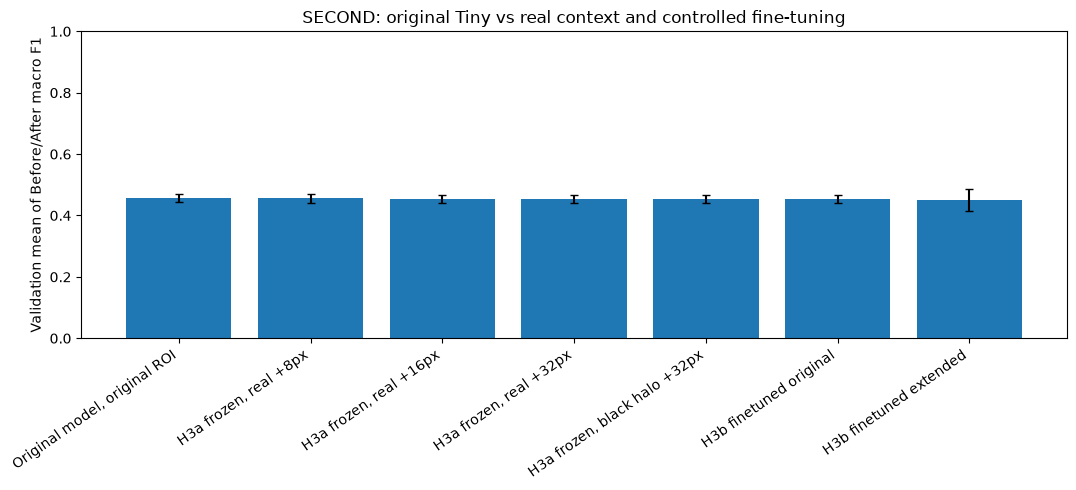


OUTPUT: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/debug/tiny_second_context_h3a_h3b_deterministic_v1/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1
Interpretation: a +0.02 F1 gap is PRACTICAL, not statistical proof.
H3a tests frozen pretrained weights. H3b tests SHORT fine-tuning from the
same pretrained checkpoint, NOT full training from scratch; both arms receive
equal added epochs. Results are validation-only and on VERIFIED matched ROIs.


In [7]:
print('\n============= FINAL MEAN F1 COMPARISON =============')
results=[]
for seed in SEEDS:
    z=h3a[(h3a.seed==seed)&(h3a.context_px==0)&(h3a.variant=='real')].iloc[0]
    results.append({'experiment':'Original model, original ROI','seed':seed,'F1':z.mean_macro_F1,
                    'joint_accuracy':z.joint_accuracy})
    for pad in CONTEXT_PX:
        if pad==0:continue
        z=h3a[(h3a.seed==seed)&(h3a.context_px==pad)&(h3a.variant=='real')].iloc[0]
        results.append({'experiment':f'H3a frozen, real +{pad}px','seed':seed,
                        'F1':z.mean_macro_F1,'joint_accuracy':z.joint_accuracy})
    z=h3a[(h3a.seed==seed)&(h3a.context_px==H3B_PADDING)&(h3a.variant=='black_halo')].iloc[0]
    results.append({'experiment':f'H3a frozen, black halo +{H3B_PADDING}px','seed':seed,
                    'F1':z.mean_macro_F1,'joint_accuracy':z.joint_accuracy})
    if RUN_H3B:
        for arm in ('original','extended'):
            z=h3b[(h3b.seed==seed)&(h3b.variant==arm)].iloc[0]
            results.append({'experiment':f'H3b finetuned {arm}','seed':seed,
                            'F1':z.mean_macro_F1,'joint_accuracy':z.joint_accuracy})
report=pd.DataFrame(results)
report.to_csv(OUT/'final_comparison_by_seed.csv',index=False)
aggregate=report.groupby('experiment',sort=False).agg(
    mean_F1=('F1','mean'),sample_std_F1=('F1','std'),
    mean_joint_accuracy=('joint_accuracy','mean'),n_seeds=('seed','size')).reset_index()
aggregate.to_csv(OUT/'final_comparison_mean_std.csv',index=False)
print(aggregate.round(5).to_string(index=False))
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(np.arange(len(aggregate)),aggregate['mean_F1'].values,
       yerr=aggregate['sample_std_F1'].fillna(0).values,capsize=3)
ax.set_xticks(np.arange(len(aggregate)))
ax.set_xticklabels(aggregate['experiment'],rotation=35,ha='right')
ax.set_ylabel('Validation mean of Before/After macro F1')
ax.set_ylim(0,1)
ax.set_title('SECOND: original Tiny vs real context and controlled fine-tuning')
fig.tight_layout()
fig.savefig(OUT/'final_comparison.png',dpi=140)
plt.show()
plt.close(fig)
print('\nOUTPUT:',OUT)
print('Interpretation: a +0.02 F1 gap is PRACTICAL, not statistical proof.')
print('H3a tests frozen pretrained weights. H3b tests SHORT fine-tuning from the')
print('same pretrained checkpoint, NOT full training from scratch; both arms receive')
print('equal added epochs. Results are validation-only and on VERIFIED matched ROIs.')